<a href="https://colab.research.google.com/github/AdelineKwakye/walmart-huricane-project/blob/main/notebooks/06-midterm-walmart/2026-10-30%20%E2%80%94%20Midterm%20Progress%20%E2%80%94%20Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

In [2]:
# set up
import pandas as pd
walmart_transactions = 'https://raw.githubusercontent.com/AdelineKwakye/walmart-huricane-project/refs/heads/main/data/walmart_transactions.csv'
store_locations = 'https://raw.githubusercontent.com/AdelineKwakye/walmart-huricane-project/refs/heads/main/data/store_locations.csv'
distribution_centers = 'https://raw.githubusercontent.com/AdelineKwakye/walmart-huricane-project/refs/heads/main/data/distribution_centers.csv'
df_transactions = pd.read_csv(walmart_transactions)
df_store = pd.read_csv(store_locations)
df_distribution_centers = pd.read_csv(distribution_centers)
df_product = pd.read_csv('https://raw.githubusercontent.com/AdelineKwakye/walmart-huricane-project/refs/heads/main/data/product_catalog.csv')

DECISIONS = []

def log(step, decision, rows_affected):
    DECISIONS.append({'step': step, 'decision': decision, 'rows': rows_affected})
    print(f'[{step}] {decision} ({rows_affected} row(s))')

def show_log():
    return pd.DataFrame(DECISIONS)
def handle_duplicates (df_name):
  before_len = len(df_name) # length before
  print("Length before cleaning duplicates: ", before_len)
  removed = df_name.duplicated().sum() # duplicated rows to be removed
  clean_dup = df_name.drop_duplicates().copy() # drop duplicates
  after_len = len(clean_dup) # length after
  print( "Length after cleaning duplicates: ", after_len)
  log('duplicates', 'dropped exact duplicate rows', removed) # log
  return clean_dup

df_clean = handle_duplicates(df_transactions)

def clean_unit_price(df_name):
    before_len = len(df_name)
    print("Length before cleaning: ", before_len)
    clean_df = df_name.copy()


    # Strip '$' and convert directly to float
    clean_df['unit_price'] = (
        clean_df['unit_price']
        .astype(str)
        .str.replace('$', '', regex=False)
        .str.strip()
        .astype(float)
    )

    assert clean_df['unit_price'].dtype == float # confirm that it's a float

    after_len = len(clean_df)
    print("Length after cleaning: ", after_len)
    log('unit price', 'stripped $ and converted to float', len(clean_df))
    return clean_df

df_clean = clean_unit_price(df_clean)
def handle_negative_values(df_name):
  # keeping negative values since representative of refunds/ returns
  # this function will just ensure that quantity is a numeric value

  before_len = len(df_name)
  print("Length before cleaning: ", before_len)
  clean_df = df_name.copy()

  clean_df['quantity'] = pd.to_numeric(clean_df['quantity'], errors="coerce") # convert to numeric

  # keep track of negative values
  negative_values = (clean_df['quantity'] < 0 ).sum()
  print("Number of negative values: ", negative_values)

  after_len = len(clean_df)
  print("Length after cleaning: ", after_len)

  log('negative quantity', 'decided to keep all of the negative quantities since it could be indicative of refunds/returns', 0)
  return clean_df

df_clean = handle_negative_values(df_clean)
def clean_store_id(df_name, table_name):
    before_len = len(df_name)
    print(f"Length before cleaning {table_name}: ", before_len)
    clean_df = df_name.copy()

    # standardize the store id to start with FL-###
    # using format that was done in previous lab/studio
    clean_df['store_id'] = (
        clean_df['store_id']
        .astype(str)
        .str.upper()
        .str.strip()
        .str.replace(r'[^A-Z0-9]', '', regex=True)
        .apply(lambda s: f'{s[:2]}-{s[2:]}')
    )

    after_len = len(clean_df)
    print(f"Length after cleaning {table_name}: ", after_len)

    log(
        f'store_id ({table_name})',
        f'standardized formatting of store_id to follow FL-### in {table_name}',
        len(clean_df),
    )
    return clean_df

df_clean = clean_store_id(df_clean, table_name='transactions') # standardize store id from transactions
df_clean_store = clean_store_id(df_store, table_name='stores') # standardize store id from stores
def clean_timestamps(df_name):
  before_len = len(df_name)
  print("Length before cleaning: ", before_len)
  clean_df = df_name.copy()

  # standardize the timestamp column so it uses space as a separator and a T

  clean_df['timestamp'] = (
      clean_df['timestamp']
      .astype(str)
      .str.strip()
      .str.replace('T', ' ', regex=False)
  )
  # convert to datetime
  clean_df['timestamp'] = pd.to_datetime(clean_df['timestamp'], format='mixed', errors='coerce')

  null_count = clean_df['timestamp'].isnull().sum()
  print("Number of null values: ", null_count)
  # drop na
  clean_df = clean_df.dropna(subset=['timestamp']).copy()

  # create normalized date column
  clean_df['date'] = clean_df['timestamp'].dt.normalize()

  after_len = len(clean_df)
  print("Length after cleaning, ", after_len)
  log('timestamp', 'standardized the separator, converted to be datetime, droped na values, and created a normalized date column ', null_count)
  return clean_df

print('nulls in df_clean: ', df_clean['timestamp'].isnull().sum())

df_clean = clean_timestamps(df_clean)
print('nulls in df_clean: ', df_clean['timestamp'].isnull().sum())
#clean category
df_clean['category']=df_clean['category'].str.strip()
df_clean['category']=df_clean['category'].str.lower()
df_clean['category']=df_clean['category'].str.replace(' ','')
df_clean['category']=df_clean['category'].str.replace('-','')

# define remapping dictionary to consolidate duplicates
category_map = {
    'groceries': 'grocery',
    'household': 'household_essentials',
    'householdessentials': 'household_essentials',
    'alcohol': 'alcoholic_beverages',
    'alcoholicbeverages': 'alcoholic_beverages',
    'emergencysupplies': 'emergency',
    'baby': 'baby_products',
    'babyproducts': 'baby_products',
    'games&entertainment': 'entertainment',
    'breakfastfoods': 'breakfast',
    'health&wellness': 'health'
}
# Apply the category remapping
df_clean['category'] = df_clean['category'].replace(category_map)

# Log the decision
log(
    'category consolidation',
    'consolidated overlapping and duplicate category names to standard categories',
    len(df_clean)
)

category_remap_extra = {
    'snacks': 'food',
    'electronics': 'entertainment'
}

df_clean['category'] = df_clean['category'].replace(category_remap_extra)

log(
    'category consolidation extra',
    "mapped 'snacks' to 'food' and 'electronics' to 'entertainment'",
    len(df_clean)
)

print("Updated Standardized Categories:", df_clean['category'].unique())
show_log()

Length before cleaning duplicates:  25562
Length after cleaning duplicates:  25532
[duplicates] dropped exact duplicate rows (30 row(s))
Length before cleaning:  25532
Length after cleaning:  25532
[unit price] stripped $ and converted to float (25532 row(s))
Length before cleaning:  25532
Number of negative values:  130
Length after cleaning:  25532
[negative quantity] decided to keep all of the negative quantities since it could be indicative of refunds/returns (0 row(s))
Length before cleaning transactions:  25532
Length after cleaning transactions:  25532
[store_id (transactions)] standardized formatting of store_id to follow FL-### in transactions (25532 row(s))
Length before cleaning stores:  14
Length after cleaning stores:  14
[store_id (stores)] standardized formatting of store_id to follow FL-### in stores (14 row(s))
nulls in df_clean:  884
Length before cleaning:  25532
Number of null values:  884
Length after cleaning,  24648
[timestamp] standardized the separator, convert

,step,decision,rows
0,duplicates,dropped exact duplicate rows,30
1,unit price,stripped $ and converted to float,25532
2,negative quantity,decided to keep all of the negative quantities...,0
3,store_id (transactions),standardized formatting of store_id to follow ...,25532
4,store_id (stores),standardized formatting of store_id to follow ...,14
5,timestamp,"standardized the separator, converted to be da...",884
6,category consolidation,consolidated overlapping and duplicate categor...,24648
7,category consolidation extra,mapped 'snacks' to 'food' and 'electronics' to...,24648


In [3]:
# TODO: the numbers
# 1. Calculate total sales (quantity * unit_price) for each transaction
df_clean['total_sales'] = df_clean['quantity'] * df_clean['unit_price']

# Define dates
landfall_date = pd.to_datetime('2024-09-26')
surge_start = pd.to_datetime('2024-09-19')
surge_end = pd.to_datetime('2024-09-25')
baseline_start = pd.to_datetime('2024-09-01')
baseline_end = pd.to_datetime('2024-09-15')

# 2. Filter into baseline and surge dataframes
df_baseline = df_clean[(df_clean['date'] >= baseline_start) & (df_clean['date'] <= baseline_end)]
df_surge = df_clean[(df_clean['date'] >= surge_start) & (df_clean['date'] <= surge_end)]

# Calculate average daily sales per category for Baseline
baseline_daily = df_baseline.groupby(['category', 'date'])['total_sales'].sum().reset_index()
baseline_avg = baseline_daily.groupby('category')['total_sales'].mean().reset_index(name='baseline_daily_avg')

# Calculate average daily sales per category for Surge window
surge_daily = df_surge.groupby(['category', 'date'])['total_sales'].sum().reset_index()
surge_avg = surge_daily.groupby('category')['total_sales'].mean().reset_index(name='surge_daily_avg')

# Merge and calculate % surge increase
surge_analysis = pd.merge(baseline_avg, surge_avg, on='category', how='inner')
surge_analysis['pct_increase'] = ((surge_analysis['surge_daily_avg'] - surge_analysis['baseline_daily_avg']) / surge_analysis['baseline_daily_avg']) * 100
surge_analysis = surge_analysis.sort_values(by='pct_increase', ascending=False)

print("=== Category Sales Surge Analysis ===")
display(surge_analysis)

top_5_categories = surge_analysis.head(5)['category'].tolist()
print(f"\nTop 5 Surging Categories: {top_5_categories}")

# Find the top product by surge multiple
baseline = df_clean[
    df_clean['date'].between('2024-09-01', '2024-09-15')
]
surge = df_clean[
    df_clean['date'].between('2024-09-19', '2024-09-25')
]

# Calculate average daily units sold by standardized category
baseline_sales = baseline.groupby('category')['quantity'].sum() / 15
surge_sales = surge.groupby('category')['quantity'].sum() / 7

results = pd.concat(
    [baseline_sales.rename('baseline_daily_avg'),
     surge_sales.rename('surge_daily_avg')],
    axis=1
).fillna(0)

# Calculate surge multiple
results = results[results['baseline_daily_avg'] > 0].copy()

results['surge_multiple'] = (
    results['surge_daily_avg'] /
    results['baseline_daily_avg']
)

# Find highest surge multiple
top = results.sort_values(
    'surge_multiple', ascending=False
).iloc[0]

top_sku = results['surge_multiple'].idxmax()
print(f"Top product: {top_sku}")
print(f"Surge multiple: {top['surge_multiple']:.2f}x")
print("Baseline window: September 1–15, 2024")
print("Surge window: September 19–25, 2024")

=== Category Sales Surge Analysis ===


,category,baseline_daily_avg,surge_daily_avg,pct_increase
2,breakfast,254.411333,1311.260000,415.409429
3,emergency,3061.710667,8782.128571,186.837312
4,entertainment,3031.786000,7486.832857,146.944635
0,alcoholic_beverages,1160.565333,2627.185714,126.371204
7,health,629.593333,1412.292857,124.318267
8,household_essentials,761.136000,1578.654286,107.407649
6,grocery,426.272000,758.551429,77.950095
1,baby_products,2325.134667,3660.170000,57.417549
5,food,521.316667,661.418571,26.874626



Top 5 Surging Categories: ['breakfast', 'emergency', 'entertainment', 'alcoholic_beverages', 'health']
Top product: breakfast
Surge multiple: 5.15x
Baseline window: September 1–15, 2024
Surge window: September 19–25, 2024


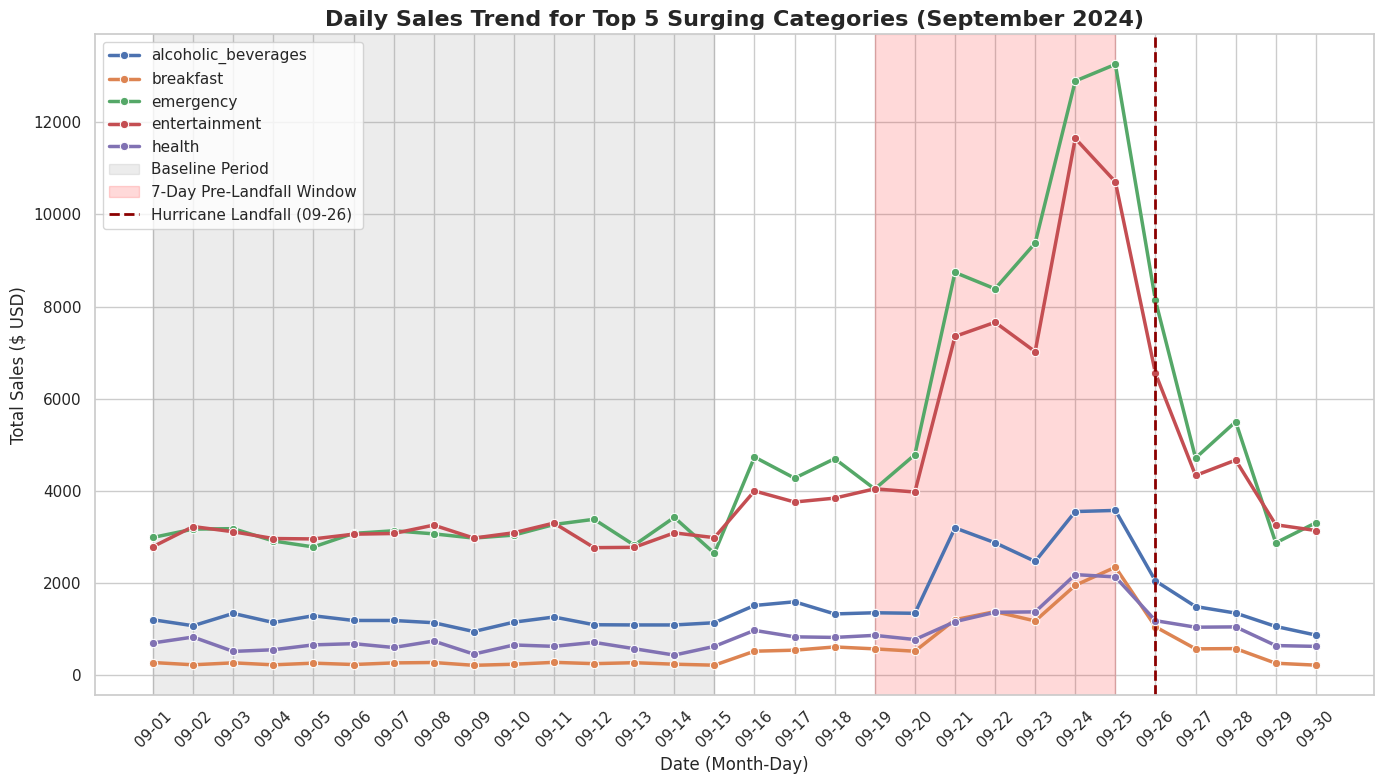

In [4]:
# TODO: the chart
import matplotlib.pyplot as plt
import seaborn as sns
# 3. Plot the daily trend for the Top 5 Surging Categories
df_daily_cat = df_clean.groupby(['category', 'date'])['total_sales'].sum().reset_index()
df_daily_cat['date_str'] = df_daily_cat['date'].dt.strftime('%m-%d')

plt.figure(figsize=(14, 8))
sns.set_theme(style="whitegrid")

# Filter for only top 5 categories
df_top5_daily = df_daily_cat[df_daily_cat['category'].isin(top_5_categories)].copy()

sns.lineplot(data=df_top5_daily, x='date_str', y='total_sales', hue='category', linewidth=2.5, marker='o')

# Highlight windows
plt.axvspan('09-01', '09-15', color='gray', alpha=0.15, label='Baseline Period')
plt.axvspan('09-19', '09-25', color='red', alpha=0.15, label='7-Day Pre-Landfall Window')
plt.axvline(x='09-26', color='darkred', linestyle='--', linewidth=2, label='Hurricane Landfall (09-26)')

plt.title('Daily Sales Trend for Top 5 Surging Categories (September 2024)', fontsize=16, fontweight='bold')
plt.xlabel('Date (Month-Day)', fontsize=12)
plt.ylabel('Total Sales ($ USD)', fontsize=12)
plt.xticks(rotation=45)
plt.legend(loc='upper left', fontsize=11)
plt.tight_layout()
plt.show()

**Q1 answer, in one sentence a manager could read:** With a 15-day baseline window period from September 1-15 and a 7-day surge window period from September 19-25, breakfast experienced the greatest relative surge at a 5.15x multiple (+415.4%).

### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

In [ ]:
# TODO

**Q2 answer:** _..._

### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

In [ ]:
# TODO

**Q3 answer, with its caveat:** _..._

### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

**Q4 (stores and geography):** _..._

**Q5 (signal or artifact):** _..._

### Self-check

In [ ]:
progress = {
    'q1_multiple': 5.15,            # TODO: a number
    'q1_baseline_window': '09-01-2024 to 09-15-2024',   # TODO: stated explicitly
    'q2_canonical_products': None,  # TODO: a number
    'q3_join_rows_preserved': None, # TODO: True/False
    'q3_days_in_correlation': None, # TODO: a number
    'charts_with_message_titles': None,  # TODO: how many
    'notebook_runs_clean': False,   # TODO: True after Restart and Run All
    'repo_pushed': False,           # TODO
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)
print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))

### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

**b)** One number you reported that you are least confident in, and why.

_your answer here_